In [1]:

get_ipython().run_line_magic('cd', '/home/ec2-user/SageMaker/project/')
get_ipython().system('conda install -c anaconda lxml -y')
get_ipython().system('pip install beautifulsoup4 matplotlib sentence-transformers --quiet')

/home/ec2-user/SageMaker/project
Channels:
 - anaconda
 - https://nexus.prod.int.tdmstudio.proquest.com/repository/conda-forge-prod
 - https://nexus.prod.int.tdmstudio.proquest.com/repository/pytorch-proxy-prod
 - https://nexus.prod.int.tdmstudio.proquest.com/repository/nvidia-proxy-prod
Platform: linux-64
Solving environment: done

## Package Plan ##

  environment location: /home/ec2-user/anaconda3/envs/JupyterSystemEnv

  added / updated specs:
    - lxml


The following packages will be downloaded:

    package                    |            build
    ---------------------------|-----------------
    libxslt-1.1.43             |       h711ed8c_1         240 KB  https://nexus.prod.int.tdmstudio.proquest.com/repository/conda-forge-prod
    lxml-6.1.0                 |  py310he6d4be0_0         1.4 MB  https://nexus.prod.int.tdmstudio.proquest.com/repository/conda-forge-prod
    ------------------------------------------------------------
                                           Tot

In [2]:

import os
import pandas as pd
from lxml import etree
from bs4 import BeautifulSoup
import importlib
import doc_meta

corpus = '/home/ec2-user/SageMaker/data/Latina/'
input_files = os.listdir(corpus)

importlib.reload(doc_meta)

res_list = []
for file in input_files:
    metadata = doc_meta.getxmlcontent(corpus, file)
    if metadata is not None:
        res_list.append(metadata)

df = pd.DataFrame(res_list)
df.columns = ['goid', 'author', 'title', 'num_date', 'publisher', 'text', 'terms_list']

# Parse dates and year
df["num_date"] = pd.to_datetime(df["num_date"], errors="coerce")
df["year"] = df["num_date"].dt.year

print(f"Total articles loaded: {df.shape[0]}")
print(f"Year range: {df['year'].min()} – {df['year'].max()}")
df.head(3)

Total articles loaded: 8259
Year range: 1968 – 2026


,goid,author,title,num_date,publisher,text,terms_list,year
0,3227710376,"Ortiz, María",El Senado aprueba una medida para eliminar los...,2025-04-02,"ImpreMedia Operating Company, LLC",Un grupo clave de republicanos del Senado crit...,"[{'tag': 'Personal', 'text': 'McConnell, Mitch...",2025
1,1941159074,"Peña, María",Sessions lanza en Boston otro “grito de guerra...,2017-09-21,"ImpreMedia Operating Company, LLC",WASHINGTON.- Al afirmar que la “MS-13” amenaza...,"[{'tag': 'TitleKeyword', 'text': 'Departamento...",2017
2,2397260077,"Ortiz, Maria",“America Strong”: Las acrobacias aéreas de los...,2020-05-02,"ImpreMedia Operating Company, LLC","En una muestra de solidaridad nacional, el Esc...","[{'tag': 'GenSubjValue', 'text': 'Coronaviruse...",2020


In [3]:

import numpy as np
from sentence_transformers import SentenceTransformer

sbert_path = "/home/ec2-user/SageMaker/Getting Started/2025.12.578/Resources/Models/nli-mpnet-base-v2/"
model = SentenceTransformer(sbert_path, local_files_only=True)

print("Embedding articles... (may take a few minutes)")
embeddings = model.encode(
    df["text"].fillna("").tolist(),
    batch_size=32,
    show_progress_bar=True,
    normalize_embeddings=True
)
embeddings = np.array(embeddings)
print(f"Done. Shape: {embeddings.shape}")


/home/ec2-user/anaconda3/envs/python3/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Loading weights: 100%|██████████| 199/199 [00:00<00:00, 19078.09it/s]


Embedding articles... (may take a few minutes)


Batches: 100%|██████████| 259/259 [06:05<00:00,  1.41s/it]

Done. Shape: (8259, 768)


In [4]:

#  Define Hispanic family themes
frames = {
    "Family Obligation":       "respect your parents, stay loyal to family, sacrifice for relatives",
    "Cultural Identity":       "preserve Hispanic traditions, language, culture, and heritage",
    "Independence & Conflict": "wanting independence from strict family expectations",
    "Emotional Support":       "family love, emotional closeness, support during hardship",
    "Immigration Struggles":   "immigrant parents working hard, financial sacrifice, adapting to America"
}

# Score every article against each theme
frame_embs = {
    name: model.encode(text, normalize_embeddings=True)
    for name, text in frames.items()
}

for name, emb in frame_embs.items():
    df[name] = embeddings @ emb

print("Theme scores added to DataFrame.")
df[["title", "year"] + list(frames.keys())].head(5)

Theme scores added to DataFrame.


,title,year,Family Obligation,Cultural Identity,Independence & Conflict,Emotional Support,Immigration Struggles
0,El Senado aprueba una medida para eliminar los...,2025,0.023772,0.253053,-0.012826,0.052325,0.197603
1,Sessions lanza en Boston otro “grito de guerra...,2017,0.007786,0.158836,0.049532,0.051281,0.137085
2,“America Strong”: Las acrobacias aéreas de los...,2020,0.084442,0.330140,0.023145,0.148355,0.208680
3,Apoyan subida de salario minimo en todo el pai...,1998,0.068771,0.260473,-0.016256,0.058819,0.195811
4,El presidente de Ucrania acusa a Rusia de atac...,2022,0.076047,0.262794,0.067415,0.019704,0.053676


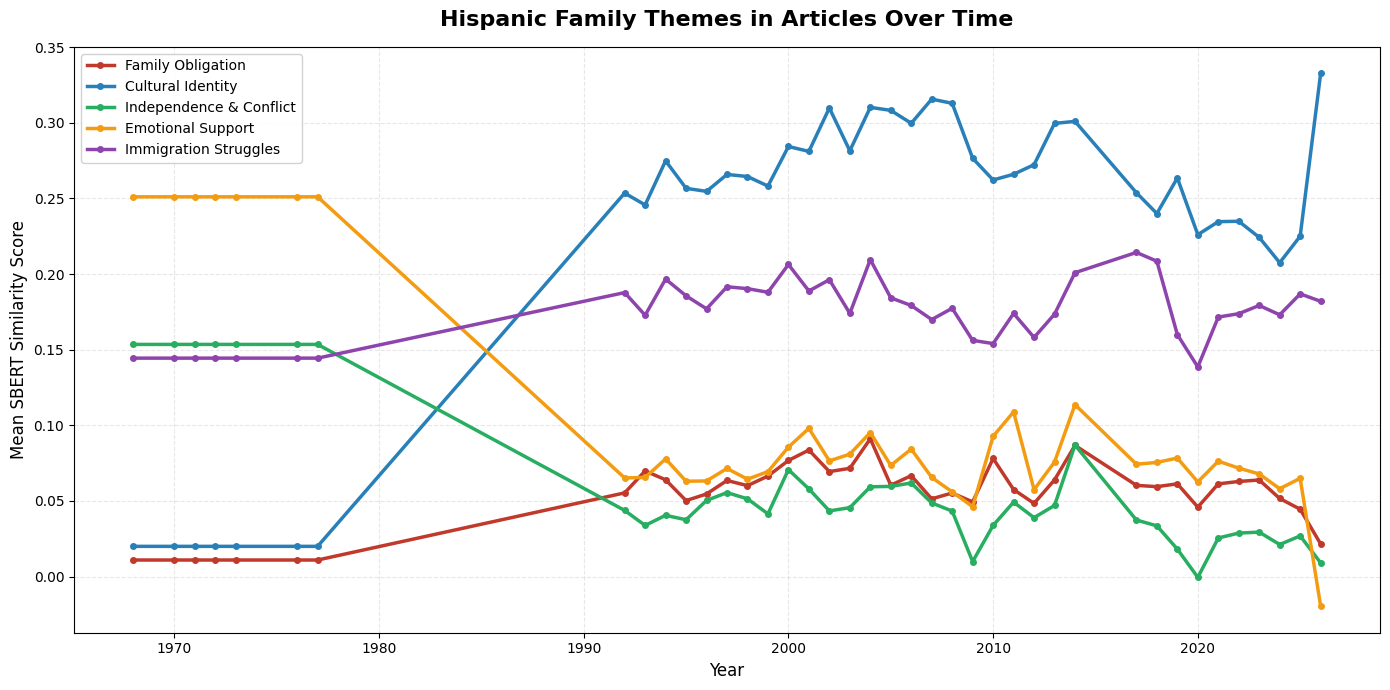

Saved: themes_over_time.png


In [5]:
#  Theme trends over time (all articles)
import matplotlib.pyplot as plt

score_cols = list(frames.keys())
yearly = df.groupby("year")[score_cols].mean()

colors = {
    "Family Obligation":       "#c0392b",
    "Cultural Identity":       "#2980b9",
    "Independence & Conflict": "#27ae60",
    "Emotional Support":       "#f39c12",
    "Immigration Struggles":   "#8e44ad"
}

fig, ax = plt.subplots(figsize=(14, 7))
for col in score_cols:
    ax.plot(yearly.index, yearly[col],
            label=col,
            color=colors[col],
            linewidth=2.5,
            marker="o", markersize=4)

ax.set_title("Hispanic Family Themes in Articles Over Time", fontsize=16, fontweight="bold", pad=15)
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Mean SBERT Similarity Score", fontsize=12)
ax.legend(loc="upper left", fontsize=10, framealpha=0.9)
ax.grid(alpha=0.3, linestyle="--")
plt.tight_layout()
plt.savefig("themes_over_time.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: themes_over_time.png")

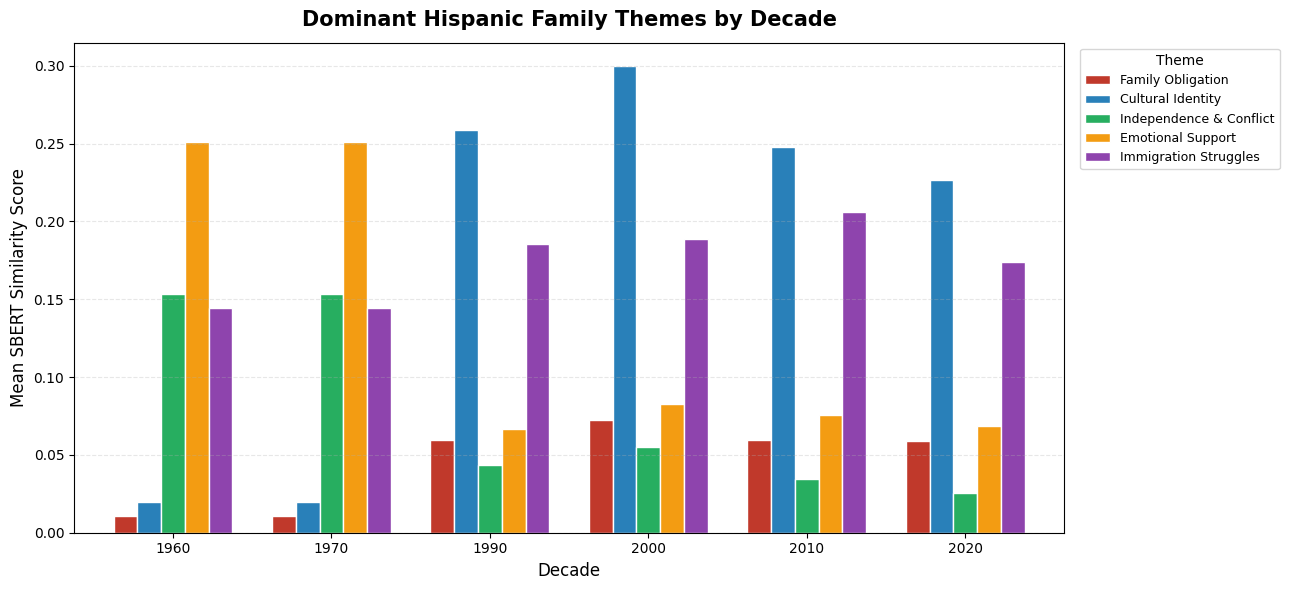

Saved: themes_by_decade.png


In [6]:
# Which theme dominates each decade?
df["decade"] = (df["year"] // 10 * 10).astype("Int64")
decade_scores = df.groupby("decade")[score_cols].mean()

fig, ax = plt.subplots(figsize=(13, 6))
decade_scores.plot(kind="bar", ax=ax,
                   color=[colors[c] for c in score_cols],
                   width=0.75, edgecolor="white")

ax.set_title("Dominant Hispanic Family Themes by Decade", fontsize=15, fontweight="bold", pad=12)
ax.set_xlabel("Decade", fontsize=12)
ax.set_ylabel("Mean SBERT Similarity Score", fontsize=12)
ax.legend(title="Theme", fontsize=9, bbox_to_anchor=(1.01, 1), loc="upper left")
ax.grid(axis="y", alpha=0.3, linestyle="--")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("themes_by_decade.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: themes_by_decade.png")

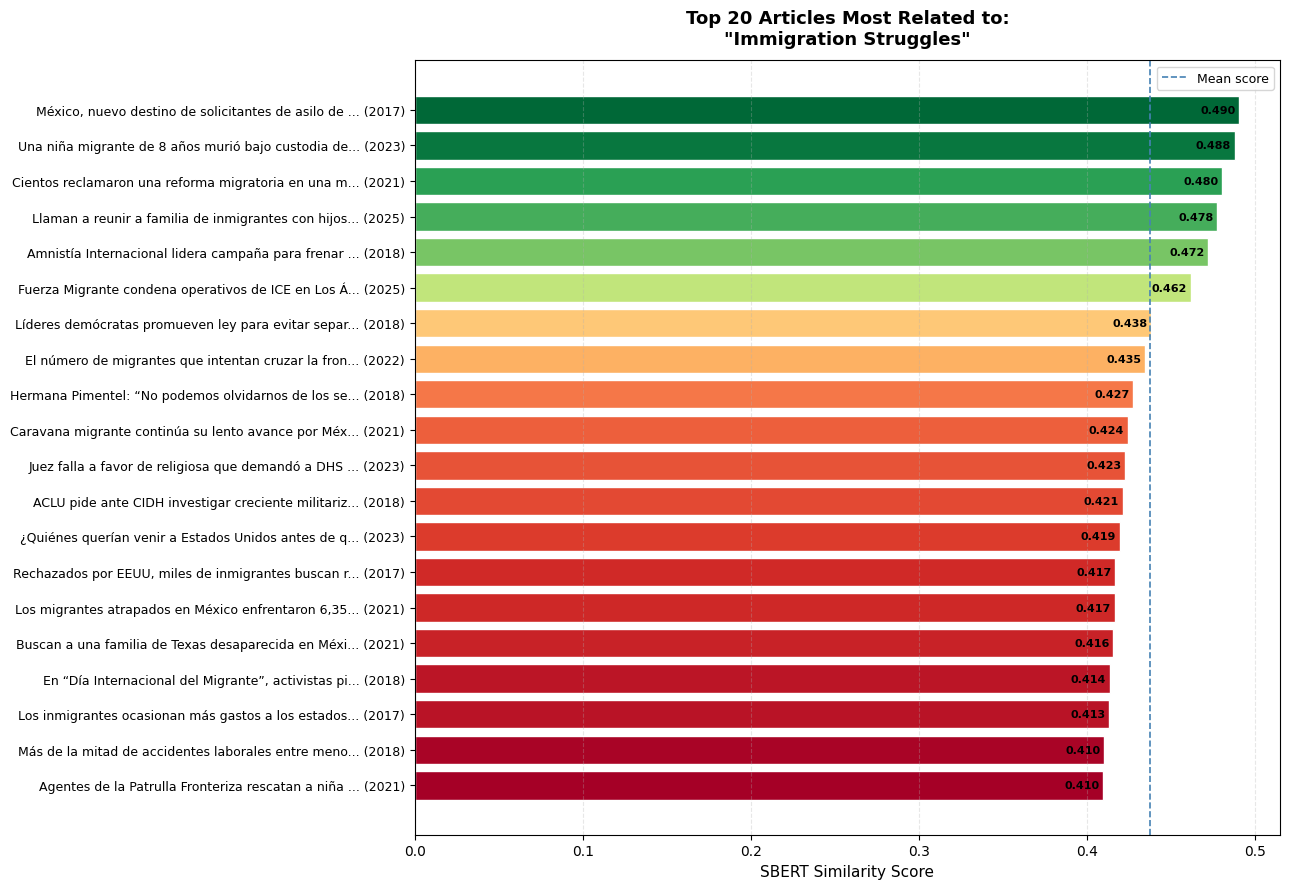

Saved top articles chart for: Immigration Struggles


In [7]:

#  Top 20 most relevant articles per theme
# Change THEME below to explore different topics
THEME = "Immigration Struggles" 

top20 = df.nlargest(20, THEME)[["title", "year", THEME]].copy()
top20["short_title"] = top20["title"].apply(
    lambda t: (t[:50] + "...") if isinstance(t, str) and len(t) > 50 else t
)
top20["label"] = top20.apply(
    lambda r: f"{r['short_title']} ({int(r['year'])})" if pd.notna(r["year"]) else r["short_title"],
    axis=1
)

norm = plt.Normalize(top20[THEME].min(), top20[THEME].max())
bar_colors = plt.cm.RdYlGn(norm(top20[THEME].values))

fig, ax = plt.subplots(figsize=(13, 9))
bars = ax.barh(top20["label"].values[::-1], top20[THEME].values[::-1],
               color=bar_colors[::-1], edgecolor="white")

for bar, val in zip(bars, top20[THEME].values[::-1]):
    ax.text(bar.get_width() - 0.002, bar.get_y() + bar.get_height() / 2,
            f"{val:.3f}", va="center", ha="right", fontsize=8, fontweight="bold")

ax.set_title(f'Top 20 Articles Most Related to:\n"{THEME}"',
             fontsize=13, fontweight="bold", pad=12)
ax.set_xlabel("SBERT Similarity Score", fontsize=11)
ax.axvline(x=top20[THEME].mean(), color="steelblue",
           linestyle="--", linewidth=1.2, label="Mean score")
ax.legend(fontsize=9)
ax.grid(axis="x", alpha=0.3, linestyle="--")
ax.tick_params(axis="y", labelsize=9)
plt.tight_layout()
plt.savefig(f"top_articles_{THEME.replace(' ', '_').replace('&','and')}.png",
            dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved top articles chart for: {THEME}")

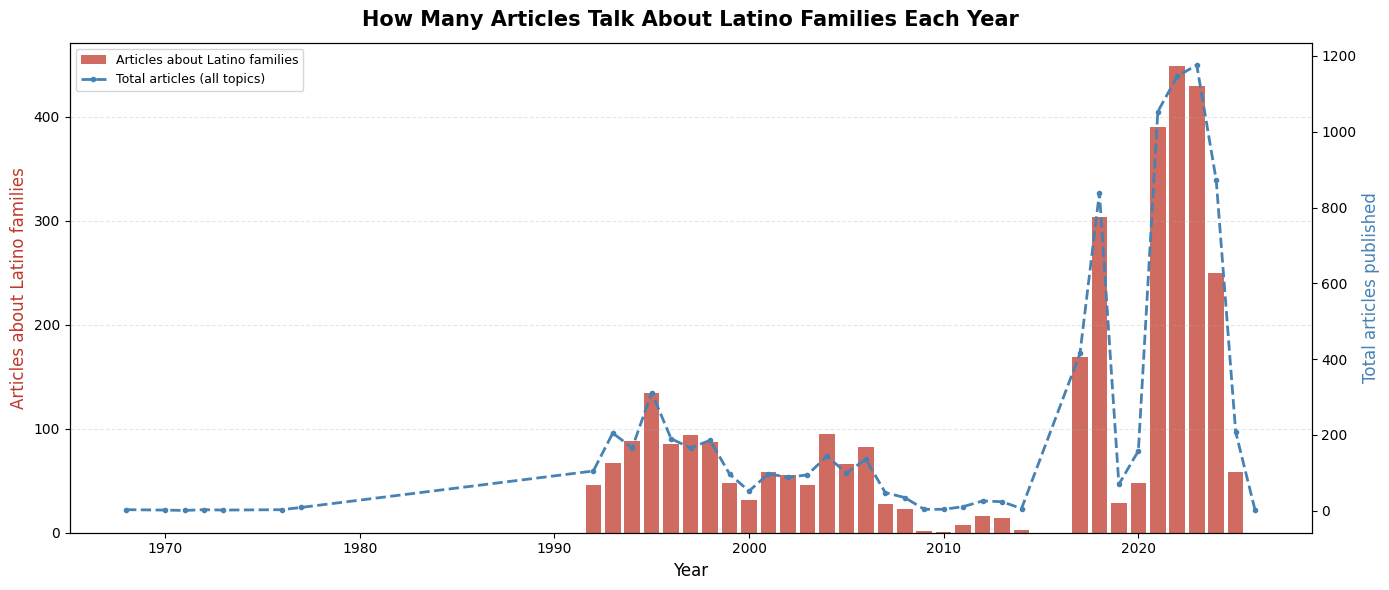

Saved: latino_family_articles_per_year.png


In [9]:
#  Number of articles about Latino families over time

import matplotlib.pyplot as plt

# Define the query
query = "Latino family Hispanic family traditions immigration"
query_emb = model.encode(query, normalize_embeddings=True)
df["family_similarity"] = embeddings @ query_emb

# Set a threshold — articles above this score "talk about" Latino families
threshold = df["family_similarity"].quantile(0.60)  # top 40% most relevant
df["about_latino_family"] = df["family_similarity"] >= threshold

# Count matching articles per year
family_by_year = df[df["about_latino_family"]].groupby("year").size()
total_by_year = df.groupby("year").size()

fig, ax = plt.subplots(figsize=(14, 6))

# Bar chart — raw count
ax.bar(family_by_year.index, family_by_year.values,
       color="#c0392b", alpha=0.75, label="Articles about Latino families")

# Line overlay — total articles that year for context
ax2 = ax.twinx()
ax2.plot(total_by_year.index, total_by_year.values,
         color="steelblue", linewidth=2, linestyle="--",
         marker="o", markersize=3, label="Total articles (all topics)")

ax.set_title("How Many Articles Talk About Latino Families Each Year",
             fontsize=15, fontweight="bold", pad=12)
ax.set_xlabel("Year", fontsize=12)
ax.set_ylabel("Articles about Latino families", fontsize=12, color="#c0392b")
ax2.set_ylabel("Total articles published", fontsize=12, color="steelblue")

lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, loc="upper left", fontsize=9)

ax.grid(axis="y", alpha=0.3, linestyle="--")
plt.tight_layout()
plt.savefig("latino_family_articles_per_year.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: latino_family_articles_per_year.png")

In [12]:
import numpy as np
from sentence_transformers import SentenceTransformer

sbert_path = "/home/ec2-user/SageMaker/Getting Started/2025.12.578/Resources/Models/nli-mpnet-base-v2/"
model = SentenceTransformer(sbert_path, local_files_only=True)

# Embed all articles
embeddings = model.encode(
    df["text"].fillna("").tolist(),
    batch_size=32,
    show_progress_bar=True,
    normalize_embeddings=True
)
embeddings = np.array(embeddings)

# Define Hispanic family themes
frames = {
    "Family Obligation":       "respect your parents, stay loyal to family, sacrifice for relatives",
    "Cultural Identity":       "preserve Hispanic traditions, language, culture, and heritage",
    "Independence & Conflict": "wanting independence from strict family expectations",
    "Emotional Support":       "family love, emotional closeness, support during hardship",
    "Immigration Struggles":   "immigrant parents working hard, financial sacrifice, adapting to America"
}

# Score each article against every theme
for name, text in frames.items():
    emb = model.encode(text, normalize_embeddings=True)
    df[name] = embeddings @ emb

# Assign each article its dominant topic (highest scoring theme)
score_cols = list(frames.keys())
df["dominant_topic"] = df[score_cols].idxmax(axis=1)

# Sort by topic then year
df_organized = df[["goid", "title", "author", "year", "publisher",
                    "dominant_topic"] + score_cols + ["text"]]\
               .sort_values(["dominant_topic", "year"])

# Save one combined CSV organized by topic
df_organized.to_csv("latina_by_topic.csv", index=False)
print("Saved: latina_by_topic.csv")

# Also save one separate CSV per topic
for topic in score_cols:
    topic_df = df_organized[df_organized["dominant_topic"] == topic]
    filename = f"latina_{topic.replace(' ', '_').replace('&', 'and')}.csv"
    topic_df.to_csv(filename, index=False)
    print(f"  {filename} — {len(topic_df)} articles")

# Summary table
print("\nArticles per topic:")
print(df_organized["dominant_topic"].value_counts().to_string())

Batches: 100%|██████████| 259/259 [05:44<00:00,  1.33s/it]


Saved: latina_by_topic.csv
  latina_Family_Obligation.csv — 6 articles
  latina_Cultural_Identity.csv — 6554 articles
  latina_Independence_and_Conflict.csv — 5 articles
  latina_Emotional_Support.csv — 57 articles
  latina_Immigration_Struggles.csv — 1637 articles

Articles per topic:
dominant_topic
Cultural Identity          6554
Immigration Struggles      1637
Emotional Support            57
Family Obligation             6
Independence & Conflict       5


In [19]:
!aws s3 cp latina_Immigration_Struggles.csv s3://pq-tdm-studio-results/tdm-ale-data/a4821/results/

upload: ./latina_Immigration_Struggles.csv to s3://pq-tdm-studio-results/tdm-ale-data/a4821/results/latina_Immigration_Struggles.csv
